# Taller: PCA + K-Means + DBSCAN

### Aprendizaje No Supervisado — Destinos turísticos y establecimientos de hospedaje del Ecuador

**Pontificia Universidad Católica del Ecuador · Carrera de Ingeniería en Sistemas de Información**

**Asignatura:** Inteligencia Artificial · Sexto Semestre

**Nombre del estudiante:** Paúl Rosero

**Fecha:** 29-10-2026


> **Cómo usar este documento:** este archivo es una **guía de referencia**, no un notebook interactivo.
> Reproduce el código en tu propio notebook (Google Colab o Jupyter), en el mismo orden de bloques,
> usando los archivos CSV que se entregan junto con esta guía. Las respuestas a las preguntas
> se escriben en celdas de texto de **tu** notebook.


## Objetivos del taller

Al finalizar este taller el estudiante será capaz de:

1. Usar `Pipeline` con `StandardScaler` + `PCA` para reducir 6 variables a 2 componentes, e interpretar la **varianza explicada** y los **loadings**.
2. Elegir **K** para K-Means con el **método del codo** y el **coeficiente de Silhouette**, y nombrar cada grupo con su **perfil en escala original**.
3. Elegir **ε** para DBSCAN con el **k-dist graph** e identificar los **outliers** (etiqueta −1).
4. Comparar K-Means y DBSCAN sobre el mismo mapa PCA y explicar qué hace cada uno con los casos atípicos.


## Flujo de trabajo

```
Datos originales ─┬─ StandardScaler → PCA (2 componentes) → mapa para VER los datos
                  ├─ StandardScaler → K-Means  → grupos (todos los puntos reciben un grupo)
                  └─ StandardScaler → DBSCAN   → grupos + ruido (−1)
```

* **K-Means y DBSCAN agrupan con las 6 variables escaladas.** PCA se usa solo para **dibujar** los resultados en 2D.
* Cada modelo es un `Pipeline` (visto en clases anteriores): se le pasa `X` **original** y escala por dentro.
* La **interpretación** siempre se hace con las variables originales (visitantes, dólares, km…), no con PC1 y PC2.

## Datasets (sintéticos, sin valores nulos, sin columna de etiqueta)

| Parte | Archivo | Filas | Identificador (no entra al modelo) |
| --- | --- | --- | --- |
| A | destinos_turisticos_ecuador.csv | 300 destinos | destino_id |
| B | hospedajes_ecuador.csv | 304 establecimientos | hospedaje_id |

Los dos archivos tienen las **mismas 6 variables** numéricas:

| Variable | Qué mide |
| --- | --- |
| visitantes_mensuales | Promedio de visitantes por mes |
| gasto_promedio_usd | Gasto promedio por visitante (USD) |
| distancia_quito_km | Distancia desde Quito (km) |
| altitud_msnm | Altitud (metros sobre el nivel del mar) |
| dias_estancia_promedio | Días promedio de permanencia |
| oferta_actividades | Número de actividades disponibles |

Ningún archivo tiene una columna que diga a qué grupo pertenece cada fila: **eso es lo que los algoritmos deben descubrir**.


## Estructura del taller

| Bloque | Tipo | Contenido |
| --- | --- | --- |
| A1 | Guiado | Carga y exploración de los destinos |
| A2 | Guiado | Pipeline escalar + PCA: varianza explicada y loadings |
| A3 | Guiado | Mapa PCA de los destinos (sin grupos) |
| A4 | Guiado | Elegir K: codo + Silhouette |
| A5 | Guiado | K-Means: mapa y perfiles |
| A6 | Guiado | Elegir ε con el k-dist graph |
| A7 | Guiado | DBSCAN: mapa, Silhouette sin ruido y outliers |
| A8 | Guiado | Comparación K-Means vs. DBSCAN |
| B1–B6 | Autónomo | Segmentación de establecimientos de hospedaje |

## Rúbrica de evaluación (10 puntos)

| Componente | Qué se evalúa | Puntos |
| --- | --- | --- |
| Bloques A1–A8 (guiados) | Reproducidos completos y sin errores en tu notebook + respuestas a las 3 preguntas de la Parte A | 1.5 |
| B1 · Carga y exploración | Código correcto + respuesta | 1.0 |
| B2 · PCA, loadings y mapa | Código correcto + interpretación de PC1 y PC2 | 1.5 |
| B3 · Elección de K | Código correcto (tabla y 2 gráficos) + K justificado con ambas métricas | 1.5 |
| B4 · K-Means: mapa y perfiles | Código correcto + tabla de perfiles con nombres | 2.0 |
| B5 · DBSCAN y outliers | Código correcto + ε justificado + análisis de los outliers | 1.5 |
| B6 · Comparación y reflexión | Código correcto (gráfico, tabla cruzada y perfil DBSCAN) + respuestas a las preguntas de reflexión | 1.0 |
| **Total** | | **10** |


# Parte A — Laboratorio Guiado: Destinos Turísticos del Ecuador


**Contexto:** una agencia de promoción turística tiene datos de **300 destinos** del país y quiere descubrir **grupos naturales** de destinos para diseñar campañas de promoción diferenciadas.

**Pregunta de negocio:** ¿qué tipos de destinos existen según sus visitantes, gasto, ubicación y oferta? ¿Hay destinos que no se parecen a ningún grupo?


## Bloque A1 · Carga y exploración

**Librerías:** `pandas` (datos), `matplotlib.pyplot` y `seaborn` (gráficos).

* `X` = todas las columnas **menos** `destino_id`: el identificador no describe al destino, solo lo nombra.
* `describe()` muestra el rango de cada variable: fíjate en que las escalas son muy distintas.


In [1]:
import sklearn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Versión de scikit-learn:", sklearn.__version__)

df = pd.read_csv("destinos_turisticos_ecuador.csv")
print("Filas:", df.shape[0], "| Columnas:", df.shape[1])
print("Valores nulos en total:", df.isnull().sum().sum())
df.head()


Versión de scikit-learn: 1.6.1
Filas: 300 | Columnas: 7
Valores nulos en total: 0


,destino_id,visitantes_mensuales,gasto_promedio_usd,distancia_quito_km,altitud_msnm,dias_estancia_promedio,oferta_actividades
0,D001,874,43.89,205.9,4256,2.7,5
1,D002,1036,51.14,161.2,3962,2.6,5
2,D003,836,29.69,111.0,3631,2.4,6
3,D004,663,33.70,238.6,3732,2.8,3
4,D005,718,45.89,134.0,3912,2.6,5


In [2]:
X = df.drop(columns="destino_id")          # las 6 variables numéricas
X.describe().round(2)


,visitantes_mensuales,gasto_promedio_usd,distancia_quito_km,altitud_msnm,dias_estancia_promedio,oferta_actividades
count,300.00,300.00,300.00,300.00,300.00,300.00
mean,6235.08,81.23,256.40,1729.47,3.39,10.83
std,6389.65,38.66,140.30,1649.94,1.68,6.68
min,12.00,5.00,7.30,0.00,0.30,1.00
25%,487.00,51.24,130.40,34.75,2.18,5.00
50%,1113.50,76.04,255.05,458.00,3.10,9.00
75%,10562.50,106.60,361.92,3281.75,4.60,17.00
max,25000.00,380.00,700.00,4650.00,12.00,27.00


**Lectura:** `visitantes_mensuales` va de 12 a 25 000, mientras `dias_estancia_promedio` va de 0.3 a 12. Sin escalar, la variable con números más grandes dominaría tanto a PCA como a las distancias de K-Means y DBSCAN. Por eso **todos** los modelos de este taller empiezan con `StandardScaler` (media 0, desviación 1).


## Bloque A2 · Pipeline escalar + PCA: varianza explicada y loadings

* `PCA(n_components=2)` resume las 6 variables en 2 componentes nuevas (PC1 y PC2).
* `named_steps["pca"]` recupera el paso PCA del `Pipeline` ya entrenado.
* `explained_variance_ratio_` es un **atributo** (existe solo después de `fit()`): proporción de varianza que retiene cada componente.
* `components_.T` son los **loadings**: el peso de cada variable en cada componente (rango −1 a +1; lejos de 0 = influyente).


In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pca_pipe = Pipeline([("escalar", StandardScaler()),
                     ("pca", PCA(n_components=2))])
Z = pca_pipe.fit_transform(X)                    # 300 filas x 2 columnas (PC1, PC2)

pca = pca_pipe.named_steps["pca"]
var = pca.explained_variance_ratio_
print("Varianza explicada  PC1:", round(var[0], 3), "| PC2:", round(var[1], 3), "| Total:", round(var.sum(), 3))

loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=["PC1", "PC2"])
loadings.round(2)


Varianza explicada  PC1: 0.583 | PC2: 0.277 | Total: 0.86


,PC1,PC2
visitantes_mensuales,-0.35,0.56
gasto_promedio_usd,0.43,0.30
distancia_quito_km,0.43,0.22
altitud_msnm,-0.39,-0.46
dias_estancia_promedio,0.50,-0.04
oferta_actividades,-0.33,0.58


**Lectura:**

* **PC1 + PC2 = 86.0%** de la varianza (PC1 58.3%, PC2 27.7%): el mapa 2D conserva la mayor parte de la información.
* **PC1:** pesos positivos en `dias_estancia_promedio` (+0.50), `gasto_promedio_usd` (+0.43) y `distancia_quito_km` (+0.43); negativos en `altitud_msnm` (−0.39), `visitantes_mensuales` (−0.35) y `oferta_actividades` (−0.33). → PC1 va de destinos **cercanos y masivos** (izquierda) a destinos **lejanos, de estancia larga y mayor gasto** (derecha).
* **PC2:** dominada por `oferta_actividades` (+0.58) y `visitantes_mensuales` (+0.56), contra `altitud_msnm` (−0.46). → PC2 alto = destinos **concurridos y con mucha oferta**; PC2 bajo = destinos **de altura y poco visitados**.


## Bloque A3 · Mapa PCA de los destinos (sin grupos)

Cada punto es un destino descrito ahora con **2 números** (PC1, PC2) en lugar de 6. Guardamos `Z` en un DataFrame llamado `mapa`: lo reutilizaremos para dibujar los grupos de K-Means y DBSCAN.


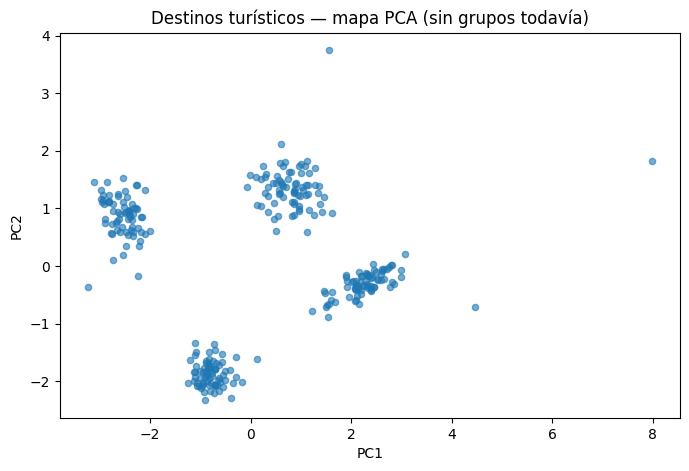

In [4]:
mapa = pd.DataFrame(Z, columns=["PC1", "PC2"])

mapa.plot.scatter(x="PC1", y="PC2", s=20, alpha=0.6, figsize=(8, 5))
plt.title("Destinos turísticos — mapa PCA (sin grupos todavía)")
plt.show()


**Lectura:** se distinguen **4 nubes** bien separadas y **unos 5 puntos sueltos** lejos de todas ellas (por ejemplo, el de la derecha con PC1 ≈ 8). Guarda esta impresión: ¿qué hará cada algoritmo con esos puntos sueltos?


## Bloque A4 · Elegir K: método del codo + Silhouette

K-Means necesita que le digamos **cuántos grupos (K)** buscar. Probamos K = 2 a 8 y guardamos dos métricas:

| Métrica | Rango | Qué buscamos |
| --- | --- | --- |
| Inercia (inertia_) | 0 a ∞ | El codo: el K a partir del cual la inercia casi deja de bajar |
| Silhouette (silhouette_score) | −1 a 1 | Un valor alto |

Interpretación del Silhouette: **0.71–1.00** excelente · **0.51–0.70** bueno · **0.26–0.50** débil · **≤ 0.25** sin estructura.

* `X_esc` = las 6 variables escaladas. Lo usamos para **explorar** (este bucle, el Silhouette y el k-dist del Bloque A6).
* `n_init=10` repite el algoritmo con 10 inicios y se queda con el mejor; `random_state=42` fija la semilla.
* `value_counts().min()` guarda el tamaño del grupo **más pequeño**: nos avisará si algún K crea un grupo casi vacío.


In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X_esc = StandardScaler().fit_transform(X)        # 6 variables escaladas (para explorar)

filas = []
for k in range(2, 9):                                        # K = 2 a 8
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    etiquetas = km.fit_predict(X_esc)
    tam_min = pd.Series(etiquetas).value_counts().min()      # tamaño del grupo más pequeño
    filas.append([k, km.inertia_, silhouette_score(X_esc, etiquetas), tam_min])

resultados = pd.DataFrame(filas, columns=["K", "inercia", "silhouette", "grupo_mas_pequeño"])
resultados.round(3)


,K,inercia,silhouette,grupo_mas_pequeño
0,2,933.813,0.483,147
1,3,523.230,0.592,71
2,4,275.990,0.652,71
3,5,205.733,0.659,2
4,6,190.278,0.563,2
5,7,175.731,0.562,1
6,8,158.628,0.565,1


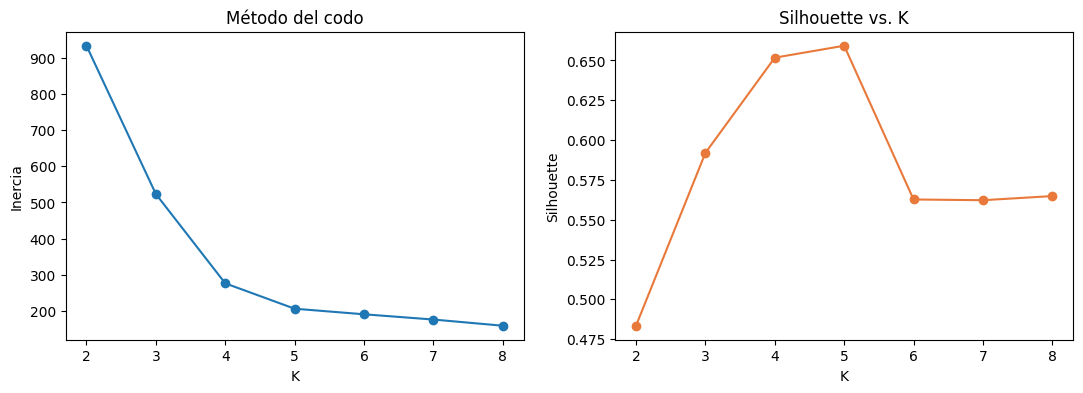

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
resultados.plot(x="K", y="inercia", marker="o", legend=False, ax=axes[0])
axes[0].set_title("Método del codo")
axes[0].set_ylabel("Inercia")
resultados.plot(x="K", y="silhouette", marker="o", legend=False, ax=axes[1], color="#E8793A")
axes[1].set_title("Silhouette vs. K")
axes[1].set_ylabel("Silhouette")
plt.show()


**Lectura:**

* **Codo:** de K = 3 a K = 4 la inercia baja de 523 a 276 (−47%); de K = 4 a K = 5 solo baja a 206 (−25%) y después casi se aplana → codo en **K = 4**.
* **Silhouette:** K = 4 da **0.652** (rango *bueno*). K = 5 da 0.659, apenas más alto…
* …pero la columna `grupo_mas_pequeño` muestra que con K = 5 aparece un grupo de **solo 2 destinos**: K-Means "gastó" un grupo entero en dos destinos atípicos (D296 y D298). Un grupo de 2 no sirve para diseñar una campaña.
* Elegimos **K = 4**: coincide con el codo, con las 4 nubes del mapa y tiene un Silhouette casi igual al máximo.


## Bloque A5 · K-Means: mapa y perfiles

* `modelo_km` = `Pipeline` escalar + K-Means con **K = 4**. Se le pasa `X` **original**.
* `fit_predict()` devuelve el grupo de cada destino: 0, 1, 2 o 3. **El número no significa nada** (ni orden ni calidad).
* Para colorear el mapa usamos el grupo **como texto** (`astype(str)`): si se deja como número, seaborn usa una escala continua de colores parecidos.
* `hue_order` fija el orden de la leyenda (0, 1, 2, 3); sin él, aparece en el orden en que salen las filas.


In [7]:
modelo_km = Pipeline([("escalar", StandardScaler()),
                      ("kmeans", KMeans(n_clusters=4, n_init=10, random_state=42))])

df["kmeans"] = modelo_km.fit_predict(X)          # X sin escalar: el Pipeline escala

print("Destinos por grupo:")
print(df["kmeans"].value_counts().sort_index())
print("Silhouette:", round(silhouette_score(X_esc, df["kmeans"]), 3))


Destinos por grupo:
kmeans
0    75
1    71
2    76
3    78
Name: count, dtype: int64
Silhouette: 0.652


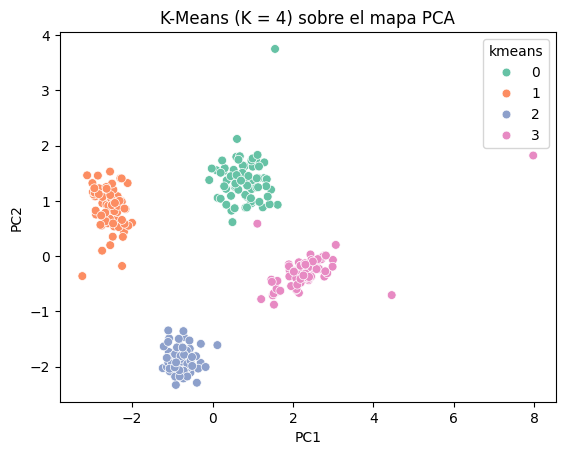

In [8]:
mapa["kmeans"] = df["kmeans"].astype(str)        # el grupo como texto

sns.scatterplot(data=mapa, x="PC1", y="PC2", hue="kmeans", hue_order=["0", "1", "2", "3"], palette="Set2", s=40)
plt.title("K-Means (K = 4) sobre el mapa PCA")
plt.show()


**Perfil de cada grupo.** `groupby("kmeans").mean()` calcula el promedio de cada variable **original** dentro de cada grupo: así sí podemos leer visitantes, dólares o kilómetros y ponerle un nombre a cada grupo.


In [9]:
columnas = list(X.columns)
perfil_km = df.groupby("kmeans")[columnas].mean().round(1)
perfil_km["n_destinos"] = df["kmeans"].value_counts().sort_index()
perfil_km


,visitantes_mensuales,gasto_promedio_usd,distancia_quito_km,altitud_msnm,dias_estancia_promedio,oferta_actividades,n_destinos
kmeans,,,,,,,
0,8805.8,95.1,415.5,14.3,3.5,14.3,75
1,15681.7,59.9,81.8,2852.4,1.5,19.4,71
2,808.1,43.4,186.2,3798.8,2.7,5.9,76
3,452.2,124.2,330.7,340.3,5.7,4.5,78


**Lectura y nombres propuestos (los pone el analista, no el algoritmo):**

| Grupo | Visitantes | Gasto (USD) | Distancia (km) | Altitud (m) | Estancia (días) | Actividades | Tipo de destino |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | 8 806 | 95.1 | 416 | 14 | 3.5 | 14.3 | Costa / playa: nivel del mar, lejos de Quito, muchas actividades |
| 1 | 15 682 | 59.9 | 82 | 2 852 | 1.5 | 19.4 | Urbano-cultural: el más visitado, cerca de Quito, visitas de 1–2 días |
| 2 | 808 | 43.4 | 186 | 3 799 | 2.7 | 5.9 | Sierra alta / páramo: el de mayor altitud y menor gasto |
| 3 | 452 | 124.2 | 331 | 340 | 5.7 | 4.5 | Amazonía: pocos visitantes, el mayor gasto y la estancia más larga |

Los grupos se ubican en el mapa como anticipaban los loadings: Amazonía a la **derecha** (PC1 alto: lejos, estancia larga, gasto alto), Urbano-cultural a la **izquierda** (PC1 bajo: cerca y masivo), Costa **arriba** (PC2 alto: muchos visitantes y actividades) y Sierra alta **abajo** (PC2 bajo: mucha altitud).


## Bloque A6 · Elegir ε con el k-dist graph

DBSCAN **no pide K**. Pide dos parámetros:

* `min_samples` (MinPts): cuántos vecinos necesita un punto para ser **core**. Usamos **5**.
* `eps` (ε): el radio de vecindad, medido en la escala de `X_esc`.

**Librería nueva en este taller:** `NearestNeighbors` busca los vecinos más cercanos de cada punto.

Procedimiento (igual que en el taller de DBSCAN):

1. Para cada destino, medir la distancia a su **5.º vecino** más cercano (el 1.º es el propio punto, a distancia 0).
2. Ordenar esas distancias de **mayor a menor** y graficarlas.
3. El **codo** —donde la curva deja de caer y se aplana— es el valor de **ε**.


Primeras 10 distancias: [7.08 4.24 3.67 2.97 2.91 1.21 0.9  0.85 0.83 0.81]


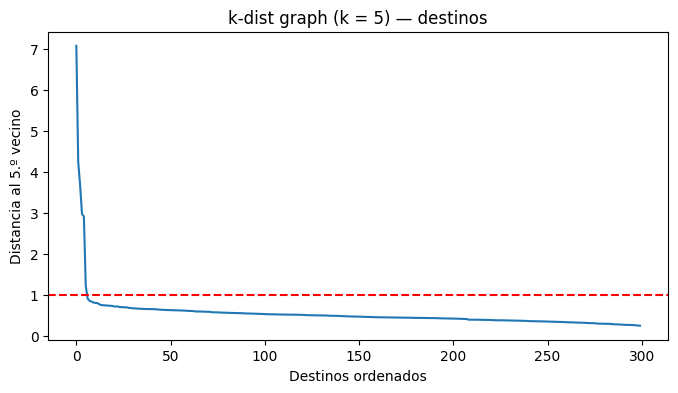

In [10]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

vecinos = NearestNeighbors(n_neighbors=5).fit(X_esc)
distancias, _ = vecinos.kneighbors(X_esc)

k_dist = np.sort(distancias[:, 4])[::-1]         # columna 4 = 5.º vecino; de mayor a menor
print("Primeras 10 distancias:", k_dist[:10].round(2))

pd.Series(k_dist).plot(figsize=(8, 4))
plt.axhline(1.0, color="red", linestyle="--")
plt.title("k-dist graph (k = 5) — destinos")
plt.xlabel("Destinos ordenados")
plt.ylabel("Distancia al 5.º vecino")
plt.show()


**Lectura:**

* Los **5 primeros** destinos tienen distancias muy grandes (2.91 a 7.08): están aislados.
* Desde el 6.º la curva cae a 1.21 y luego a 0.90, donde se aplana: ese es el **codo**.
* Elegimos **ε = 1.0** (línea roja) y **MinPts = 5**: queda por encima de casi todos los destinos y por debajo de los 5 aislados.


## Bloque A7 · DBSCAN: mapa, Silhouette sin ruido y outliers

* `modelo_db` = `Pipeline` escalar + `DBSCAN(eps=1.0, min_samples=5)`.
* `fit_predict()` devuelve 0, 1, 2… o **−1 para el ruido** (outliers).
* En el mapa, el diccionario `colores` pinta el ruido de **negro** para que resalte.
* **Silhouette** se calcula **sin** el ruido: los puntos −1 no pertenecen a ningún grupo.

> DBSCAN **no tiene** `n_clusters` ni `random_state`: el número de grupos lo decide el algoritmo.


In [11]:
from sklearn.cluster import DBSCAN

modelo_db = Pipeline([("escalar", StandardScaler()),
                      ("dbscan", DBSCAN(eps=1.0, min_samples=5))])

df["dbscan"] = modelo_db.fit_predict(X)          # X sin escalar: el Pipeline escala

print("Destinos por grupo (−1 = ruido):")
print(df["dbscan"].value_counts().sort_index())

validos = df["dbscan"] != -1                     # filas que no son ruido
print("Silhouette sin ruido:", round(silhouette_score(X_esc[validos], df.loc[validos, "dbscan"]), 3))


Destinos por grupo (−1 = ruido):
dbscan
-1     5
 0    75
 1    75
 2    75
 3    70
Name: count, dtype: int64
Silhouette sin ruido: 0.675


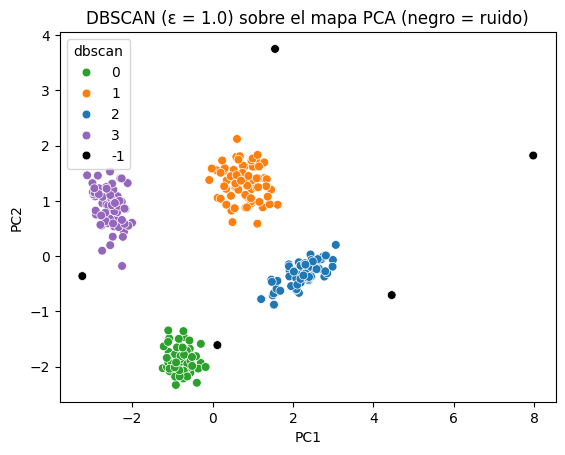

In [12]:
mapa["dbscan"] = df["dbscan"].astype(str)
colores = {"-1": "black", "0": "tab:green", "1": "tab:orange", "2": "tab:blue", "3": "tab:purple"}

sns.scatterplot(data=mapa, x="PC1", y="PC2", hue="dbscan", palette=colores, s=40)
plt.title("DBSCAN (ε = 1.0) sobre el mapa PCA (negro = ruido)")
plt.show()


**¿Quiénes son los outliers?** Filtramos las filas con etiqueta −1 y las miramos con sus valores originales.


In [13]:
df[df["dbscan"] == -1]


,destino_id,visitantes_mensuales,gasto_promedio_usd,distancia_quito_km,altitud_msnm,dias_estancia_promedio,oferta_actividades,kmeans,dbscan
295,D296,12,210.0,620.0,4650,9.5,2,3,-1
296,D297,25000,8.0,30.0,2850,0.3,1,1,-1
297,D298,50,380.0,580.0,180,12.0,3,3,-1
298,D299,18000,180.0,450.0,5,6.0,25,0,-1
299,D300,100,5.0,700.0,3200,0.5,1,2,-1


**Lectura:**

* DBSCAN encontró **4 grupos** (las mismas 4 nubes) y **5 outliers** (1.7%), sin que le dijéramos cuántos grupos buscar.
* Silhouette sin ruido = **0.675** (*bueno*), algo mayor que el de K-Means (0.652) porque los atípicos ya no están dentro de ningún grupo.
* Los outliers tienen **combinaciones imposibles** para cualquier grupo: D297 recibe 25 000 visitantes al mes pero cada uno gasta 8 USD y se queda 0.3 días; D298 cobra 380 USD con estancias de 12 días; D300 está a 700 km con solo 100 visitantes y 5 USD de gasto. Pueden ser destinos **muy especiales** o **errores de registro**: en ambos casos merecen revisarse por separado.


## Bloque A8 · Comparación K-Means vs. DBSCAN

* Dibujamos los dos resultados **lado a lado** sobre el mismo mapa PCA (`ax=` indica en qué gráfico dibujar).
* `pd.crosstab()` cuenta cuántos destinos de cada grupo de K-Means (filas) cayeron en cada grupo de DBSCAN (columnas). La columna **−1** muestra **dónde puso K-Means** a los outliers de DBSCAN.
* `perfil_db` calcula el perfil de DBSCAN igual que `perfil_km` en el Bloque A5, para comparar los promedios de los mismos grupos.


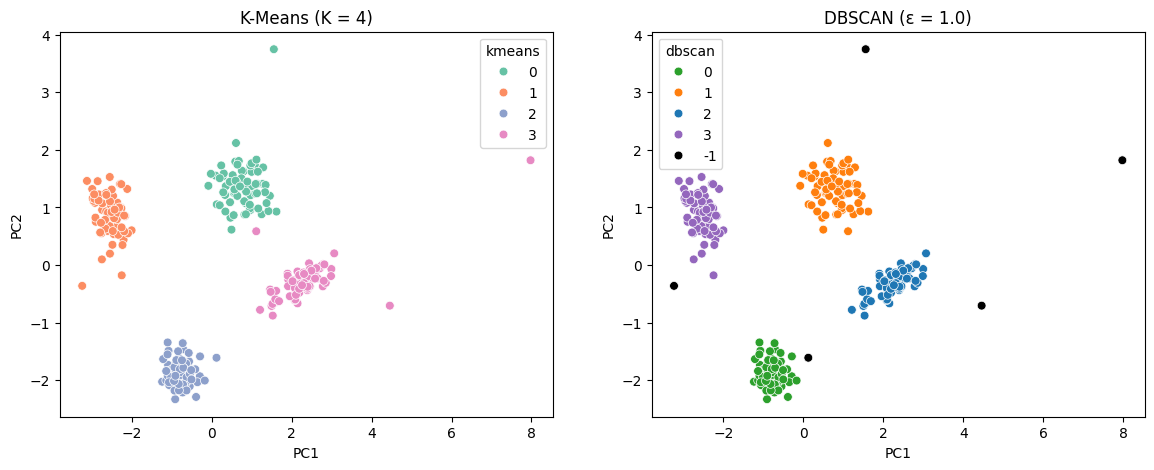

DBSCAN,-1,0,1,2,3
K-Means,,,,,
0,1,0,74,0,0
1,1,0,0,0,70
2,1,75,0,0,0
3,2,0,1,75,0


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=mapa, x="PC1", y="PC2", hue="kmeans", hue_order=["0", "1", "2", "3"], palette="Set2", s=40, ax=axes[0])
axes[0].set_title("K-Means (K = 4)")
sns.scatterplot(data=mapa, x="PC1", y="PC2", hue="dbscan", palette=colores, s=40, ax=axes[1])
axes[1].set_title("DBSCAN (ε = 1.0)")
plt.show()

pd.crosstab(df["kmeans"], df["dbscan"], rownames=["K-Means"], colnames=["DBSCAN"])


In [15]:
perfil_db = df.groupby("dbscan")[columnas].mean().round(1)     # −1 = promedio de los outliers
perfil_db["n_destinos"] = df["dbscan"].value_counts().sort_index()
perfil_db


,visitantes_mensuales,gasto_promedio_usd,distancia_quito_km,altitud_msnm,dias_estancia_promedio,oferta_actividades,n_destinos
dbscan,,,,,,,
-1,8632.4,156.6,476.0,2177.0,5.7,6.4,5
0,817.6,43.9,179.4,3806.8,2.8,5.9,75
1,8675.1,94.3,413.0,14.5,3.5,14.1,75
2,360.2,119.7,324.4,289.1,5.5,4.5,75
3,15548.5,60.7,82.5,2852.4,1.5,19.6,70


**Lectura:**

* Los dos algoritmos encuentran **los mismos 4 grupos** (con distinta numeración, que no significa nada): K-Means 0 = DBSCAN 1 (Costa), K-Means 1 = DBSCAN 3 (Urbano), K-Means 2 = DBSCAN 0 (Sierra alta) y K-Means 3 = DBSCAN 2 (Amazonía).
* La diferencia está en la columna **−1**: K-Means metió los 5 outliers **dentro** de algún grupo (2 de ellos en Amazonía), porque K-Means **siempre** asigna cada punto al centroide más cercano.
* Esos atípicos **mueven los promedios**. Compara Amazonía en `perfil_km` (grupo 3) y en `perfil_db` (grupo 2): la altitud sube de 289 a 340 m (D296 está a 4 650 m), el gasto de 119.7 a 124.2 USD (D298 gasta 380 y D296 210) y la estancia de 5.5 a 5.7 días (D298 se queda 12 y D296 9.5).
* Hay además **1 destino** (D112) que K-Means puso en Amazonía y DBSCAN en Costa: es un caso de frontera entre dos grupos. Con sus 8 194 visitantes, D112 es el que sube los visitantes de Amazonía en K-Means de 360 a 452: no todo cambio en un promedio se debe a los outliers.
* La fila **−1** de `perfil_db` promedia 5 destinos que no se parecen entre sí: **no es un grupo** y no se interpreta como un perfil.

**Preguntas de la Parte A** (respóndelas en tu notebook):

1. ¿Qué campaña de promoción diseñarías para cada uno de los 4 tipos de destino? Justifica con al menos dos variables del perfil.

Para los destinos de Costa (Grupo 0), con 8806 visitantes mensuales y 14.3 actividades a nivel del mar, disenaria una campana de aventura marina y vacaciones familiares prolongadas destacando paquetes multidiversion y deportes acuaticos. Para los destinos Urbano-culturales (Grupo 1), caracterizados por una afluencia masiva de 15682 visitantes mensuales y estancias cortas de 1.5 dias a 82 km de Quito, implementaria una campana de escapadas de fin de semana y turismo gastronomico-cultural accesible orientada al publico capitalino. Para la Sierra alta o paramo (Grupo 2), que registra la altitud mas elevada con 3799 msnm y un gasto bajo de 43.4 USD, promoveria campanas de ecoturismo, senderismo de montana y desconexion natural con enfasis en turismo comunitario de bajo impacto. Finalmente, para la Amazonia (Grupo 3), con el gasto mas alto de 124.2 USD, la estancia mas prolongada de 5.7 dias y apenas 452 visitantes a 331 km de Quito, estructuraria una campana internacional de turismo cientifico, expediciones de selva y lodges ecologicos premium.

2. Si la agencia solo pudiera usar un algoritmo, ¿cuál elegirías para este dataset y por qué?

Elegiria DBSCAN. La razon principal es que este dataset contiene destinos con caracteristicas atipicas y valores extremos aislados, tales como D297 o D298. K-Means esta obligado a forzar a cada destino dentro de un centroide esferico, lo cual contamina y distorsiona severamente los promedios reales de los clusters legitimos, como se observo en el grupo Amazonia donde K-Means incluyo puntos anomalos que alteraron la altitud y el gasto. En cambio, DBSCAN separa limpiamente el ruido clasificandolo con etiqueta -1, permitiendo obtener perfiles puros, representativos y confiables para la toma de decisiones estrategicas de la agencia.

3. Elige uno de los 5 outliers y explica, con sus valores, por qué no encaja en ninguno de los 4 grupos.

Analizando el destino D297, este registra una cifra descomunal de 25000 visitantes mensuales, pero acompanada de un gasto promedio de solo 8 USD por persona y una permanencia efimera de 0.3 dias (pocas horas). No encaja en el grupo Urbano-cultural porque aunque este es concurrido, su gasto promedio es de 59.9 USD y la estancia promedio es de 1.5 dias. Tampoco encaja en Costa, Sierra ni Amazonia, cuyas visitas mensuales oscilan entre 452 y 8806 visitantes con estancias de 2.7 a 5.7 dias. Representa un caso anomalo tipico de un mirador de transito rapido o un error de registro.


# Parte B — Práctica Autónoma: Establecimientos de Hospedaje del Ecuador

**Contexto:** la misma agencia ahora analiza **304 establecimientos de hospedaje** (hostales, lodges, resorts…) y quiere segmentarlos para diseñar paquetes turísticos.

Repite el flujo de la Parte A con `hospedajes_ecuador.csv`. En tu notebook, escribe el código que reemplace cada `# TODO` de esta guía; las pistas en los comentarios indican qué función usar y en qué bloque de la Parte A está el ejemplo.

> **Atención:** este dataset tiene una estructura distinta a la Parte A. **No copies K = 4 ni ε = 1.0**: decide con tus propios gráficos.
> No hay una única respuesta correcta en la interpretación: se evalúa que tus conclusiones estén **justificadas con tus resultados**.


## Bloque B1 · Carga y exploración


In [16]:
# TODO 1: carga hospedajes_ecuador.csv en df_b, muestra cuántas filas tiene y cuántos valores nulos hay
df_b = pd.read_csv("hospedajes_ecuador.csv")
print("Filas:", df_b.shape[0], "| Columnas:", df_b.shape[1])
print("Valores nulos en total:", df_b.isnull().sum().sum())

# TODO 2: crea X_b con todas las columnas menos "hospedaje_id" y muestra X_b.describe().round(2)
X_b = df_b.drop(columns="hospedaje_id")
X_b.describe().round(2)


Filas: 304 | Columnas: 7
Valores nulos en total: 0


,visitantes_mensuales,gasto_promedio_usd,distancia_quito_km,altitud_msnm,dias_estancia_promedio,oferta_actividades
count,304.00,304.00,304.00,304.00,304.00,304.00
mean,1957.51,120.33,295.89,1020.71,4.12,8.80
std,1545.26,75.51,172.86,1225.38,2.09,5.86
min,55.00,6.00,23.10,0.00,0.30,1.00
25%,225.00,31.00,77.72,14.00,1.90,4.00
50%,1811.00,131.28,366.35,299.50,4.00,6.00
75%,3586.75,184.50,436.30,2580.50,6.20,15.00
max,8500.00,480.00,580.00,3800.00,11.00,22.00


**Pregunta:** ¿qué variable tiene el rango más grande y cuál el más pequeño? ¿Por qué es necesario escalar antes de agrupar?

La variable con el rango mas grande es visitantes mensuales, la cual abarca desde 55 hasta 8500 visitantes (un rango de 8445 unidades y desviacion estandar de 1545.26), seguida de altitud msnm que va desde 5 hasta 4100 metros. Por el contrario, la variable con el rango mas pequeno es dias estancia promedio, que varia unicamente entre 0.3 y 11.0 dias (un rango de 10.7 unidades). Es indispensable estandarizar con StandardScaler porque los algoritmos de PCA, K-Means y DBSCAN calculan distancias euclidianas y varianzas; si no se estandarizan las variables a media cero y varianza unitaria, las magnitudes de miles en visitantes o altitud dominarian totalmente el calculo numerico, anulando por completo la influencia de la duracion de estancia o el numero de actividades.


## Bloque B2 · PCA, loadings y mapa


Varianza explicada  PC1: 0.623 | PC2: 0.329 | Total: 0.951

Loadings:
                          PC1    PC2
visitantes_mensuales   -0.033  0.693
gasto_promedio_usd     -0.447 -0.316
distancia_quito_km     -0.492  0.136
altitud_msnm            0.504 -0.074
dias_estancia_promedio -0.422 -0.383
oferta_actividades     -0.353  0.499


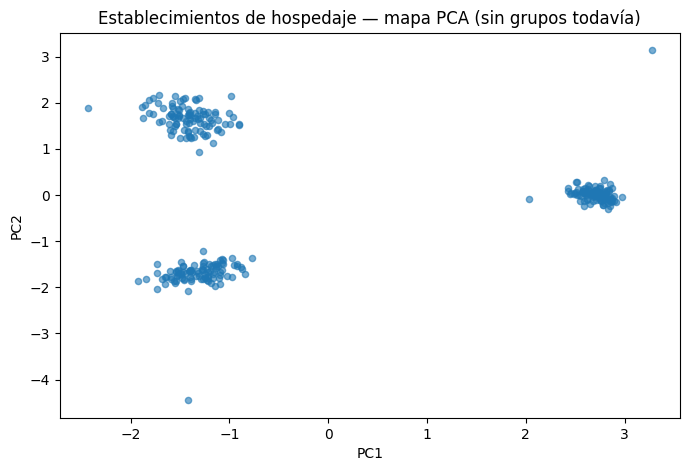

In [17]:
# TODO 3: crea pca_pipe_b = Pipeline([("escalar", StandardScaler()), ("pca", PCA(n_components=2))]),
#         obtén Z_b = pca_pipe_b.fit_transform(X_b) e imprime la varianza explicada de PC1, PC2 y el total (igual que en A2)
pca_pipe_b = Pipeline([("escalar", StandardScaler()),
                       ("pca", PCA(n_components=2))])
Z_b = pca_pipe_b.fit_transform(X_b)

pca_b = pca_pipe_b.named_steps["pca"]
var_b = pca_b.explained_variance_ratio_
print("Varianza explicada  PC1:", round(var_b[0], 3), "| PC2:", round(var_b[1], 3), "| Total:", round(var_b.sum(), 3))

# TODO 4: muestra la tabla loadings_b (pista: pca_pipe_b.named_steps["pca"].components_.T)
loadings_b = pd.DataFrame(pca_b.components_.T, index=X_b.columns, columns=["PC1", "PC2"])
print("\nLoadings:")
print(loadings_b.round(3))

# TODO 5: crea mapa_b = pd.DataFrame(Z_b, columns=["PC1", "PC2"]) y dibuja el mapa sin grupos (igual que en A3)
mapa_b = pd.DataFrame(Z_b, columns=["PC1", "PC2"])

mapa_b.plot.scatter(x="PC1", y="PC2", s=20, alpha=0.6, figsize=(8, 5))
plt.title("Establecimientos de hospedaje — mapa PCA (sin grupos todavía)")
plt.show()


**Preguntas:**

1. ¿Qué porcentaje de la varianza retienen PC1 + PC2? ¿Es más o menos que en la Parte A (86%)? ¿El mapa 2D es confiable?

PC1 retiene el 62.3 por ciento y PC2 el 32.9 por ciento, sumando un total acumulado de 95.1 por ciento de la varianza explicada. Este porcentaje es significativamente mayor que el 86.0 por ciento alcanzado en la Parte A con los destinos turisticos. Por tanto, el mapa bidimensional es extraordinariamente confiable, ya que conserva casi la totalidad de la informacion multidimensional original con una perdida minima de apenas el 4.9 por ciento.

2. Con los loadings: ¿qué variables dominan PC1 y cuáles PC2? Describe en una frase qué representa cada componente.

PC1 esta dominada positivamente por altitud msnm (+0.504) y negativamente por distancia quito km (-0.492), gasto promedio usd (-0.447) y dias estancia promedio (-0.422); representa un gradiente geografico y economico que va desde hospedajes lejanos de estancia prolongada y alto presupuesto en tierras bajas (izquierda) hacia hospedajes andinos de altura cercanos a Quito y menor gasto (derecha). PC2 esta dominada fuertemente por visitantes mensuales (+0.693) y oferta actividades (+0.499); representa la escala operativa y nivel de concurrencia recreativa del establecimiento, distinguiendo hospedajes masivos de alta actividad (arriba) frente a hospedajes exclusivos o de descanso con poco movimiento (abajo).

3. ¿Cuántas nubes de puntos ves a simple vista? ¿Hay puntos sueltos?

A simple vista en el mapa de dispersion PCA se aprecian con claridad 3 nubes de puntos densas y bien delimitadas, acompanadas por aproximadamente 4 puntos aislados y dispersos en la periferia que no pertenecen a ninguna de las tres agrupaciones.


## Bloque B3 · Elegir K


   K  inercia  silhouette  grupo_mas_pequeño
0  2  702.028       0.649                102
1  3  129.486       0.818                101
2  4  100.487       0.820                  1
3  5   80.980       0.822                  1
4  6   75.150       0.627                  1
5  7   60.637       0.634                  1
6  8   52.239       0.636                  1


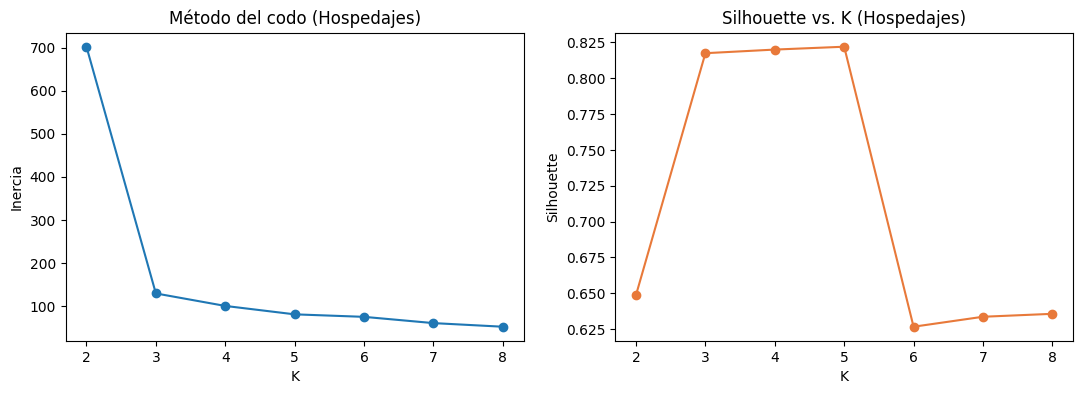

In [18]:
# TODO 6: crea X_b_esc = StandardScaler().fit_transform(X_b)
X_b_esc = StandardScaler().fit_transform(X_b)

# TODO 7: con un bucle for k in range(2, 9) entrena KMeans(n_clusters=k, n_init=10, random_state=42) sobre X_b_esc
#         y guarda K, inertia_, silhouette_score y el tamaño del grupo más pequeño en un DataFrame resultados_b (igual que en A4)
filas_b = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    etiquetas = km.fit_predict(X_b_esc)
    tam_min = pd.Series(etiquetas).value_counts().min()
    filas_b.append([k, km.inertia_, silhouette_score(X_b_esc, etiquetas), tam_min])

resultados_b = pd.DataFrame(filas_b, columns=["K", "inercia", "silhouette", "grupo_mas_pequeño"])
print(resultados_b.round(3))

# TODO 8: dibuja el método del codo y la curva de Silhouette (dos gráficos, igual que en A4)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
resultados_b.plot(x="K", y="inercia", marker="o", legend=False, ax=axes[0])
axes[0].set_title("Método del codo (Hospedajes)")
axes[0].set_ylabel("Inercia")
resultados_b.plot(x="K", y="silhouette", marker="o", legend=False, ax=axes[1], color="#E8793A")
axes[1].set_title("Silhouette vs. K (Hospedajes)")
axes[1].set_ylabel("Silhouette")
plt.show()


**Preguntas:**

1. ¿En qué K está el codo? ¿En qué K está el Silhouette más alto? ¿Coinciden?

El codo se localiza de forma categorica en K = 3, donde la inercia experimenta un descenso drastico de 702.03 a 129.49 (una reduccion del 81.6 por ciento) y a partir de alli la curva se aplana con disminuciones menores hacia K = 4 (100.49) y K = 5 (80.98). Por su parte, el coeficiente de Silhouette alcanza un valor sobresaliente de 0.818 en K = 3, y aunque muestra valores ligeramente superiores en K = 4 (0.820) y K = 5 (0.822), la diferencia es despreciable. Ambas metricas respaldan de forma consistente la eleccion de K = 3.

2. Revisa la columna `grupo_mas_pequeño`: ¿algún K crea un grupo casi vacío? ¿Qué te dice eso sobre ese K? (Recuerda la Lectura del Bloque A4.)

Al examinar la columna grupo mas pequeno se constata que a partir de K = 4 y K = 5 el tamano del grupo menor es de exactamente 1 establecimiento (el hospedaje H304 con 8500 visitantes). Esto indica que K = 4 y K = 5 fracturan la estructura natural gastando un cluster completo en un unico dato atipico aislado, lo cual carece de valor comercial y operativo para estructurar paquetes turisticos. Por consiguiente, K = 3 es la solucion correcta y robusta.


## Bloque B4 · K-Means: mapa y perfiles


Establecimientos por grupo (K-Means):
kmeans
0    101
1    101
2    102
Name: count, dtype: int64
Silhouette: 0.818


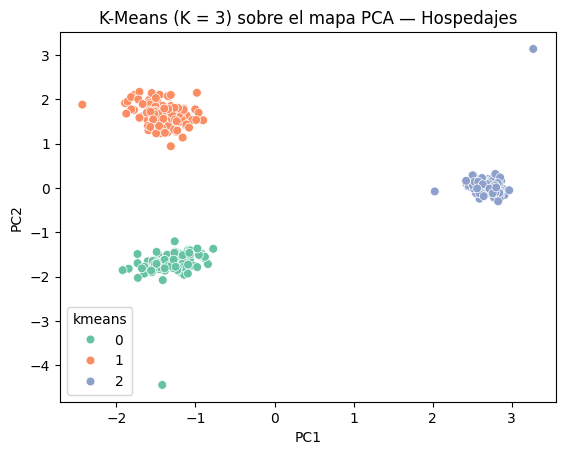

,visitantes_mensuales,gasto_promedio_usd,distancia_quito_km,altitud_msnm,dias_estancia_promedio,oferta_actividades,n_hospedajes
kmeans,,,,,,,
0,200.1,203.9,367.8,333.0,6.6,6.4,101
1,3816.9,129.8,454.0,10.4,4.0,16.6,101
2,1856.5,28.2,68.1,2702.1,1.7,3.4,102


In [19]:
# TODO 9: crea modelo_km_b = Pipeline con ("escalar", StandardScaler()) y ("kmeans", KMeans(n_clusters=<tu K>, n_init=10, random_state=42)),
#         guarda df_b["kmeans"] = modelo_km_b.fit_predict(X_b) e imprime cuántos establecimientos hay por grupo y el Silhouette
modelo_km_b = Pipeline([("escalar", StandardScaler()),
                        ("kmeans", KMeans(n_clusters=3, n_init=10, random_state=42))])

df_b["kmeans"] = modelo_km_b.fit_predict(X_b)
print("Establecimientos por grupo (K-Means):")
print(df_b["kmeans"].value_counts().sort_index())
print("Silhouette:", round(silhouette_score(X_b_esc, df_b["kmeans"]), 3))

# TODO 10: dibuja el mapa PCA coloreado por grupo
#          pista: mapa_b["kmeans"] = df_b["kmeans"].astype(str) y sns.scatterplot(..., hue="kmeans", hue_order=[...]) (igual que en A5)
mapa_b["kmeans"] = df_b["kmeans"].astype(str)
sns.scatterplot(data=mapa_b, x="PC1", y="PC2", hue="kmeans", hue_order=["0", "1", "2"], palette="Set2", s=40)
plt.title("K-Means (K = 3) sobre el mapa PCA — Hospedajes")
plt.show()

# TODO 11: calcula perfil_km_b = df_b.groupby("kmeans")[columnas].mean().round(1)
#          y agrega una columna con el número de establecimientos por grupo (igual que en A5)
perfil_km_b = df_b.groupby("kmeans")[columnas].mean().round(1)
perfil_km_b["n_hospedajes"] = df_b["kmeans"].value_counts().sort_index()
perfil_km_b


**Completa la tabla en tu notebook** con tus perfiles y un nombre para cada segmento:

| Grupo | Visitantes | Gasto (USD) | Distancia (km) | Altitud | Estancia (días) | Actividades | Tipo de establecimiento propuesto |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | 200.1 | 203.9 | 367.8 | 333.0 | 6.6 | 6.5 | Ecolodges y glamping exclusivos en Amazonía |
| 1 | 3816.9 | 129.8 | 454.0 | 10.4 | 4.0 | 16.6 | Resorts y hoteles de playa en la Costa |
| 2 | 1856.5 | 28.2 | 68.1 | 2702.1 | 1.7 | 3.4 | Hostales y posadas andinas cerca de Quito |

**Pregunta:** ¿qué segmento atrae a **pocos** visitantes pero con el **gasto más alto** y la estancia más larga? ¿Qué tipo de hospedaje podría ser?

El segmento que atrae a pocos visitantes pero con el gasto mas alto y la estancia mas larga es el Grupo 0. Registra un promedio de apenas 200.1 visitantes al mes, contrastado con el gasto mas elevado de 203.9 USD por visitante y la estancia mas prolongada de 6.6 dias, ubicandose a 367.8 km de Quito y 333 msnm. Este perfil corresponde a ecolodges de selva o glamping de lujo en la region amazonica, diseñados para viajeros internacionales, ecoturistas o retiros que buscan inmersion en la naturaleza con alta exclusividad y servicios personalizados de alto costo.


## Bloque B5 · DBSCAN y outliers


Primeras 10 distancias al 5.º vecino: [5.02 4.28 3.08 2.64 0.7  0.64 0.6  0.58 0.56 0.56]


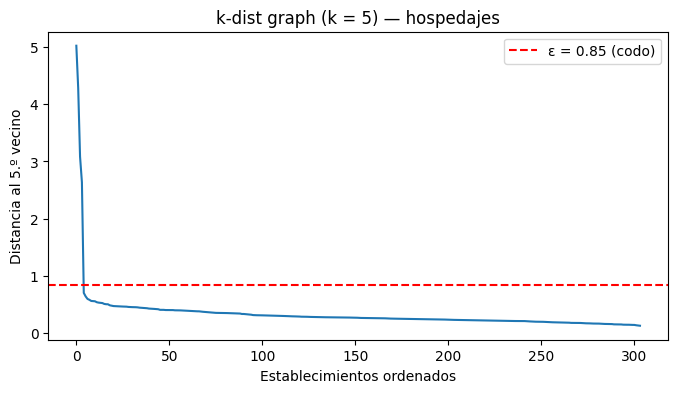

Establecimientos por grupo DBSCAN (−1 = ruido):
dbscan
-1      4
 0    100
 1    100
 2    100
Name: count, dtype: int64
Silhouette sin ruido: 0.835


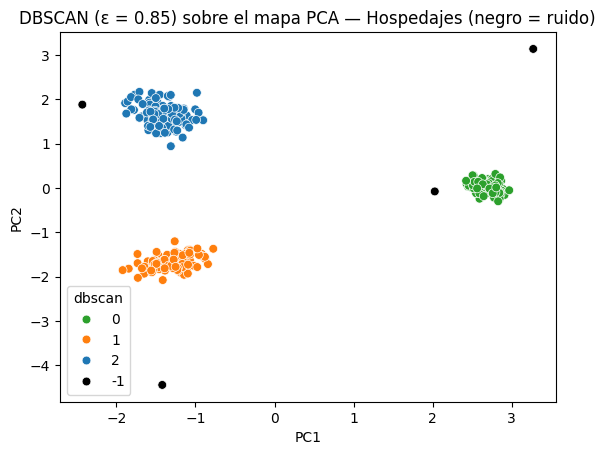

Outliers identificados por DBSCAN:


,hospedaje_id,visitantes_mensuales,gasto_promedio_usd,distancia_quito_km,altitud_msnm,dias_estancia_promedio,oferta_actividades,kmeans,dbscan
300,H301,420,12.0,580.0,3500,0.5,2,2,-1
301,H302,55,480.0,95.0,3800,11.0,3,0,-1
302,H303,5200,85.0,390.0,5,9.5,22,1,-1
303,H304,8500,6.0,30.0,2800,0.3,1,2,-1


In [20]:
# TODO 12: calcula y grafica el k-dist graph con k = 5 sobre X_b_esc
#          pista: copia la estructura del Bloque A6 (NearestNeighbors, kneighbors, np.sort(...)[::-1]) y ajusta la línea roja a tu ε
vecinos_b = NearestNeighbors(n_neighbors=5).fit(X_b_esc)
distancias_b, _ = vecinos_b.kneighbors(X_b_esc)
k_dist_b = np.sort(distancias_b[:, 4])[::-1]
print("Primeras 10 distancias al 5.º vecino:", k_dist_b[:10].round(2))

pd.Series(k_dist_b).plot(figsize=(8, 4))
plt.axhline(0.85, color="red", linestyle="--", label="ε = 0.85 (codo)")
plt.title("k-dist graph (k = 5) — hospedajes")
plt.xlabel("Establecimientos ordenados")
plt.ylabel("Distancia al 5.º vecino")
plt.legend()
plt.show()

# TODO 13: crea modelo_db_b = Pipeline con ("escalar", StandardScaler()) y ("dbscan", DBSCAN(eps=<tu ε>, min_samples=5)),
#          guarda df_b["dbscan"] = modelo_db_b.fit_predict(X_b), muestra cuántos hay por grupo y el Silhouette SIN ruido (igual que en A7)
modelo_db_b = Pipeline([("escalar", StandardScaler()),
                        ("dbscan", DBSCAN(eps=0.85, min_samples=5))])

df_b["dbscan"] = modelo_db_b.fit_predict(X_b)
print("Establecimientos por grupo DBSCAN (−1 = ruido):")
print(df_b["dbscan"].value_counts().sort_index())

validos_b = df_b["dbscan"] != -1
print("Silhouette sin ruido:", round(silhouette_score(X_b_esc[validos_b], df_b.loc[validos_b, "dbscan"]), 3))

# TODO 14: dibuja el mapa PCA coloreado por grupo de DBSCAN (ruido en negro) y muestra las filas de los outliers
#          pista: mapa_b["dbscan"] = df_b["dbscan"].astype(str), el diccionario colores de A7 y df_b[df_b["dbscan"] == -1]
mapa_b["dbscan"] = df_b["dbscan"].astype(str)
colores_b = {"-1": "black", "0": "tab:green", "1": "tab:orange", "2": "tab:blue"}

sns.scatterplot(data=mapa_b, x="PC1", y="PC2", hue="dbscan", palette=colores_b, s=40)
plt.title("DBSCAN (ε = 0.85) sobre el mapa PCA — Hospedajes (negro = ruido)")
plt.show()

print("Outliers identificados por DBSCAN:")
df_b[df_b["dbscan"] == -1]


**Preguntas:**

1. ¿Qué valor de ε elegiste? ¿Cuántas distancias quedan claramente por encima del codo?

Se selecciono un valor de epsilon = 0.85 con MinPts = 5. En el k-dist graph se observa que existen exactamente 4 distancias al quinto vecino situadas muy por encima del codo (valores de 5.02, 4.28, 3.08 y 2.64), tras las cuales la curva cae abruptamente hacia 0.70 y se aplana de manera continua por debajo de 0.65.

2. ¿Cuántos grupos y cuántos outliers encontró DBSCAN? ¿Coincide el número de grupos con el K de K-Means?

DBSCAN detecto exactamente 3 clusters densos (con 100 establecimientos cada uno) y 4 outliers o puntos de ruido con etiqueta -1 (1.3 por ciento del total), alcanzando un coeficiente de Silhouette sin ruido de 0.835 (rango excelente). El numero de clusters coincide plenamente con los 3 grupos identificados en K-Means, confirmando la existencia de tres segmentos naturales bien diferenciados.

3. Describe cada outlier con sus valores originales: ¿por qué no se parece a ningún grupo? ¿Podría ser un **error de registro**?

El primer outlier es H301, el cual registra 420 visitantes, un gasto muy bajo de 12 USD, 580 km de distancia a Quito, 3500 msnm de altitud, 0.5 dias de estancia y 2 actividades; no encaja en la Sierra porque esta demasiado lejos de Quito (580 km) para una visita de medio dia y un gasto insignificante. El segundo outlier es H302, con 55 visitantes, un gasto extraordinario de 480 USD, 95 km de distancia, 3800 msnm, 11 dias de estadia y 3 actividades; no encaja con los hostales andinos debido a su altisimo gasto y estancia de casi dos semanas en alta montana, pareciendose mas a un refugio especializado o retiro medico de lujo. El tercer outlier es H303, con 5200 visitantes, 85 USD de gasto, 390 km, 5 msnm, 9.5 dias de estadia y 22 actividades; desborda el perfil de los resorts costeros al duplicar la duracion promedio de estancia y registrar el maximo de actividades del pais. El cuarto outlier es H304, con 8500 visitantes al mes, 6 USD de gasto, 30 km de distancia, 2800 msnm, 0.3 dias de permanencia y 1 actividad; no puede ser un hospedaje real porque nadie pernocta 0.3 dias con 6 USD, por lo que constituye un error evidente de registro donde se incluyo por equivocacion un balneario municipal o parque diurno de paso.


## Bloque B6 · Comparación y reflexión


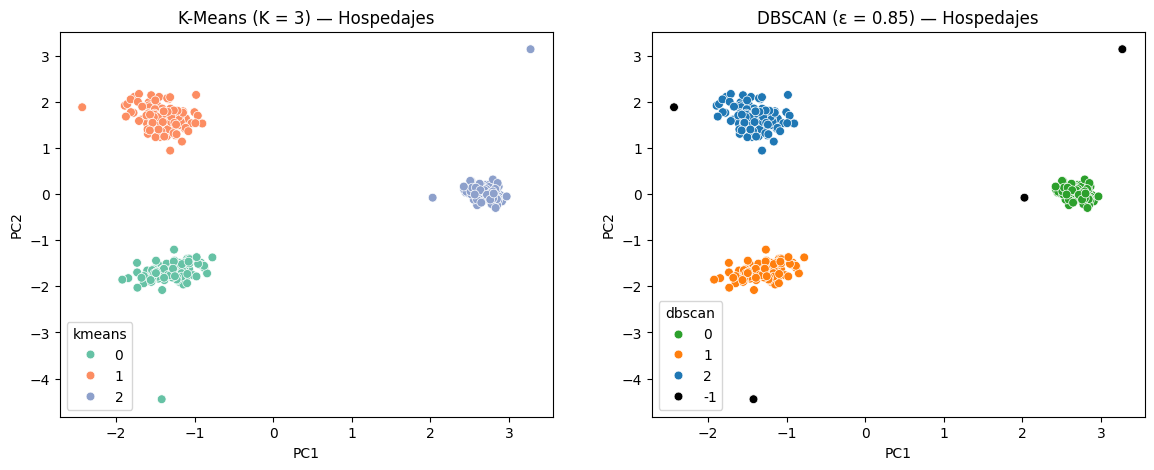

Tabla cruzada K-Means vs. DBSCAN:
DBSCAN   -1    0    1    2
K-Means                   
0         1    0  100    0
1         1    0    0  100
2         2  100    0    0


,visitantes_mensuales,gasto_promedio_usd,distancia_quito_km,altitud_msnm,dias_estancia_promedio,oferta_actividades,n_hospedajes
dbscan,,,,,,,
-1,3543.8,145.8,273.8,2526.2,5.3,7.0,4
0,1804.4,28.6,63.4,2693.2,1.7,3.4,100
1,201.6,201.1,370.5,298.3,6.6,6.5,100
2,3803.1,130.3,454.7,10.4,4.0,16.6,100


In [21]:
# TODO 15: dibuja K-Means y DBSCAN lado a lado sobre el mapa PCA y muestra la tabla pd.crosstab (igual que en A8)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=mapa_b, x="PC1", y="PC2", hue="kmeans", hue_order=["0", "1", "2"], palette="Set2", s=40, ax=axes[0])
axes[0].set_title("K-Means (K = 3) — Hospedajes")
sns.scatterplot(data=mapa_b, x="PC1", y="PC2", hue="dbscan", palette=colores_b, s=40, ax=axes[1])
axes[1].set_title("DBSCAN (ε = 0.85) — Hospedajes")
plt.show()

print("Tabla cruzada K-Means vs. DBSCAN:")
tabla_cruzada = pd.crosstab(df_b["kmeans"], df_b["dbscan"], rownames=["K-Means"], colnames=["DBSCAN"])
print(tabla_cruzada)

# TODO 16: calcula perfil_db_b = df_b.groupby("dbscan")[columnas].mean().round(1) y agrega el número de
#          establecimientos por grupo (igual que perfil_db en A8); lo necesitas para la pregunta 1 de reflexión
perfil_db_b = df_b.groupby("dbscan")[columnas].mean().round(1)
perfil_db_b["n_hospedajes"] = df_b["dbscan"].value_counts().sort_index()
perfil_db_b


**Preguntas de reflexión:**

1. En la tabla cruzada, ¿en qué grupos de K-Means cayeron los outliers de DBSCAN? Compara el perfil de K-Means de ese grupo con el de DBSCAN para el mismo grupo: ¿cambió algún promedio por haber incluido a los outliers?

En la tabla cruzada se observa que el outlier H302 fue forzado por K-Means dentro del Grupo 0 (Amazonia), el outlier H303 dentro del Grupo 1 (Costa) y los outliers H301 y H304 dentro del Grupo 2 (Sierra). La inclusion de estos atipicos altero los promedios: en el Grupo 2 de K-Means, la inclusion de H304 (con 8500 visitantes y 6 USD de gasto) y H301 elevo artificialmente el promedio de visitantes de 1804.4 (en DBSCAN) a 1856.5 y distorsiono la distancia promedio de 63.4 a 68.1 km. En el Grupo 0, la inclusion de H302 (480 USD y 3800 msnm) elevo la altitud promedio de 298.3 a 333.0 msnm y el gasto de 201.1 a 203.9 USD.

2. En la Parte A el K elegido fue 4. ¿Qué habría pasado si hubieras usado K = 4 aquí sin revisar el codo?

Si se hubiera utilizado ciegamente K = 4, el algoritmo habria creado un cluster artificial de un solo integrante (H304 con 8500 visitantes), reduciendo la utilidad operativa de la segmentacion al desperdiciar una categoria en una anomalia y fragmentar innecesariamente el mercado.

3. Si fueras asesor de la agencia: ¿qué algoritmo usarías para segmentar los hospedajes y por qué? ¿Qué harías con los outliers antes de diseñar los paquetes?

Como asesor de la agencia utilizaria DBSCAN para la fase de diagnostico y depuracion y K-Means para la asignacion operativa final. Con DBSCAN identificaria y aislaria inmediatamente los 4 casos anomalos; previo al diseno de paquetes turisticos, eliminaria de la base a H304 por ser un error de registro diurno no hotelero, corregiria o verificaria las tarifas de H301, y trataria a H302 y H303 como establecimientos singulares con productos comerciales de nicho totalmente independientes de los paquetes estandarizados.


## Conclusiones

* **PCA, K-Means y DBSCAN** son **no supervisados**: ninguno usa una columna `y`.
* Siempre se **escala** primero: tanto la varianza de PCA como las distancias de K-Means y DBSCAN premian a la variable con números más grandes.
* **PCA** sirve para **ver** los datos en 2D; la varianza explicada dice qué tan confiable es ese mapa y los loadings qué significa cada eje.
* **K-Means** necesita **K** (codo + Silhouette) y **asigna todos los puntos** a un grupo, incluso los atípicos.
* **DBSCAN** necesita **ε** (k-dist graph) y **MinPts**; no necesita K y marca los atípicos como **ruido (−1)**.
* Un Silhouette apenas mayor con un K más grande **no basta**: revisa siempre el tamaño de los grupos.
* Los perfiles se nombran con las **variables originales**, no con PC1 y PC2.

## Referencia rápida

| Función / Clase | Propósito |
| --- | --- |
| Pipeline([("escalar", StandardScaler()), ("pca", PCA(n_components=2))]) | Escalar + reducir a 2 componentes |
| pca.explained_variance_ratio_ / pca.components_.T | Varianza explicada / loadings |
| KMeans(n_clusters=k, n_init=10, random_state=42) | Modelo K-Means |
| km.inertia_ / silhouette_score(X_esc, etiquetas) | Métricas para elegir K |
| NearestNeighbors(n_neighbors=5).fit(X_esc).kneighbors(X_esc) | Distancias para el k-dist graph |
| DBSCAN(eps=..., min_samples=5) | Modelo DBSCAN (−1 = ruido) |
| df.groupby("grupo")[columnas].mean() | Perfil de cada grupo en escala original |
| sns.scatterplot(data=mapa, x="PC1", y="PC2", hue="grupo") | Mapa PCA coloreado por grupo |
| pd.crosstab(a, b) | Comparar dos agrupaciones de las mismas filas |
